<a href="https://colab.research.google.com/github/Zaza01-coder/south_africa_maize_yield_ml/blob/main/project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd

# 1. Load the exact CSV file you found
df = pd.read_csv("air_quality_historical.csv")

# 2. Display the first 5 rows and all 12 column names
print(df.head())
print("\nAll 12 columns:", df.columns.tolist())

# 3. Check data types and missing values
print("\nDataset summary:")
print(df.info())
print("\nMissing values per column:")
print(df.isnull().sum())

         date       pm10      pm2_5  carbon_monoxide  nitrogen_dioxide  \
0  2022-08-01        NaN        NaN              NaN               NaN   
1  2022-08-02        NaN        NaN              NaN               NaN   
2  2022-08-03        NaN        NaN              NaN               NaN   
3  2022-08-04  51.018182  35.250000       578.272727         44.254545   
4  2022-08-05  53.708333  37.395833       593.916667         49.029167   

   sulphur_dioxide      ozone  aerosol_optical_depth  dust  uv_index  \
0              NaN        NaN                    NaN   NaN       NaN   
1              NaN        NaN                    NaN   NaN       NaN   
2              NaN        NaN                    NaN   NaN       NaN   
3        78.568182  43.590909               0.184091   0.0  1.136364   
4       108.762500  43.375000               0.075833   0.0  1.325000   

       us_aqi  european_aqi  
0         NaN           NaN  
1         NaN           NaN  
2         NaN           NaN  
3 

In [10]:
# 1. Print all 12 column names and missing counts clearly
print("Columns:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

# 2. Convert 'date' from text to a real datetime format
df["date"] = pd.to_datetime(df["date"])

# 3. Extract Month and Year so we can analyze seasonal pollution spikes
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.strftime("%b")

# 4. Drop rows where core pollutant readings (pm2_5 and pm10) are missing
df_clean = df.dropna(subset=["pm2_5", "pm10"]).copy()

print("\nRows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print(df_clean[["date", "month_name", "pm2_5", "pm10"]].head())

Columns: ['date', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'aerosol_optical_depth', 'dust', 'uv_index', 'us_aqi', 'european_aqi', 'year', 'month', 'month_name']

Missing values per column:
date                     0
pm10                     3
pm2_5                    3
carbon_monoxide          3
nitrogen_dioxide         3
sulphur_dioxide          3
ozone                    3
aerosol_optical_depth    3
dust                     3
uv_index                 3
us_aqi                   4
european_aqi             4
year                     0
month                    0
month_name               0
dtype: int64

Rows before cleaning: 1298
Rows after cleaning: 1295
        date month_name      pm2_5       pm10
3 2022-08-04        Aug  35.250000  51.018182
4 2022-08-05        Aug  37.395833  53.708333
5 2022-08-06        Aug  48.350000  69.162500
6 2022-08-07        Aug  28.762500  41.275000
7 2022-08-08        Aug  11.958333  17.245833


Final clean row count: 1294


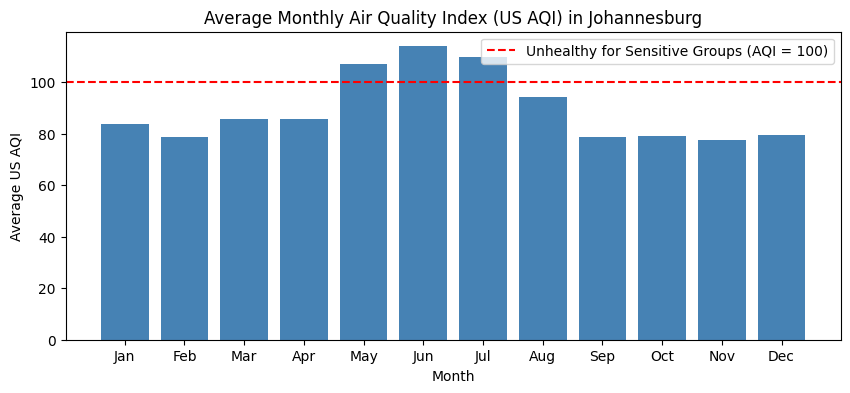

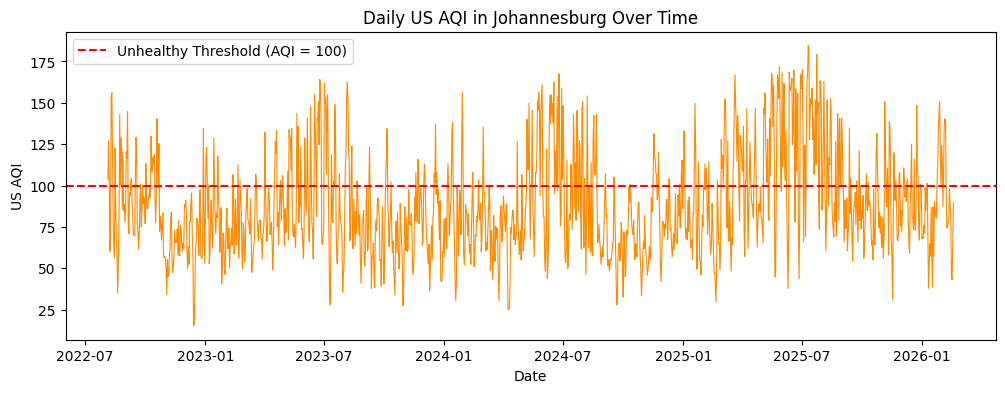

In [11]:
import matplotlib.pyplot as plt

# 1. Remove all 4 rows that contain any missing values
df_clean = df.dropna().copy()
print("Final clean row count:", len(df_clean))

# 2. Group by month number so Jan -> Dec stays in calendar order
monthly_avg = df_clean.groupby(["month", "month_name"])[["us_aqi", "pm2_5"]].mean().reset_index()

# 3. Chart 1: Average Air Quality Index (US AQI) by Month
plt.figure(figsize=(10, 4))
plt.bar(monthly_avg["month_name"], monthly_avg["us_aqi"], color="steelblue")
plt.axhline(100, color="red", linestyle="--", label="Unhealthy for Sensitive Groups (AQI = 100)")
plt.title("Average Monthly Air Quality Index (US AQI) in Johannesburg")
plt.xlabel("Month")
plt.ylabel("Average US AQI")
plt.legend()
plt.show()

# 4. Chart 2: Daily Air Quality Over Time
plt.figure(figsize=(12, 4))
plt.plot(df_clean["date"], df_clean["us_aqi"], color="darkorange", linewidth=0.8)
plt.axhline(100, color="red", linestyle="--", label="Unhealthy Threshold (AQI = 100)")
plt.title("Daily US AQI in Johannesburg Over Time")
plt.xlabel("Date")
plt.ylabel("US AQI")
plt.legend()
plt.show()

In [14]:
plt.savefig("monthly_aqi_chart.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

Average Prediction Error (MAE): 15.34 AQI points

Top Drivers of Tomorrow's AQI:
pm2_5               0.697485
us_aqi              0.087075
ozone               0.050730
sulphur_dioxide     0.045686
nitrogen_dioxide    0.034182
pm10                0.034178
carbon_monoxide     0.031738
month               0.018925
dtype: float64


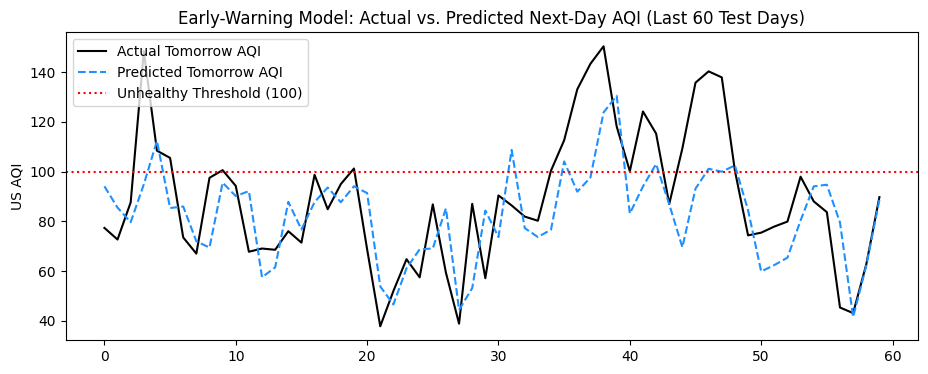

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create the target column: tomorrow's US AQI (shifted back by 1 day)
df_model = df_clean.sort_values("date").copy()
df_model["tomorrow_aqi"] = df_model["us_aqi"].shift(-1)
df_model = df_model.dropna().copy()

# 2. Pick today's features to predict tomorrow's air quality
features = ["month", "pm2_5", "pm10", "carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide", "ozone", "us_aqi"]
X = df_model[features]
y = df_model["tomorrow_aqi"]

# 3. Split by time: train on the first 80% of days, test on the most recent 20%
split = int(len(df_model) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# 4. Train the model and make predictions
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

# 5. Measure average error in AQI points
mae = mean_absolute_error(y_test, predictions)
print(f"Average Prediction Error (MAE): {mae:.2f} AQI points")

# 6. Check which pollutant matters most for predicting tomorrow's air quality
importance = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("\nTop Drivers of Tomorrow's AQI:")
print(importance)

# 7. Plot Actual vs. Predicted AQI for the last 60 test days
plt.figure(figsize=(11, 4))
plt.plot(y_test.values[-60:], label="Actual Tomorrow AQI", color="black")
plt.plot(predictions[-60:], label="Predicted Tomorrow AQI", color="dodgerblue", linestyle="--")
plt.axhline(100, color="red", linestyle=":", label="Unhealthy Threshold (100)")
plt.title("Early-Warning Model: Actual vs. Predicted Next-Day AQI (Last 60 Test Days)")
plt.ylabel("US AQI")
plt.legend()
plt.show()

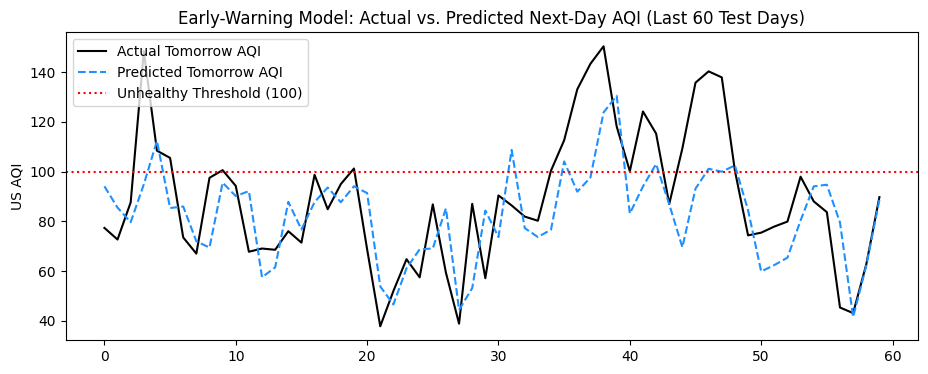

In [13]:
plt.figure(figsize=(11, 4))
plt.plot(y_test.values[-60:], label="Actual Tomorrow AQI", color="black")
plt.plot(predictions[-60:], label="Predicted Tomorrow AQI", color="dodgerblue", linestyle="--")
plt.axhline(100, color="red", linestyle=":", label="Unhealthy Threshold (100)")
plt.title("Early-Warning Model: Actual vs. Predicted Next-Day AQI (Last 60 Test Days)")
plt.ylabel("US AQI")
plt.legend()

# Save high-resolution image BEFORE plt.show()
plt.savefig("aqi_prediction_chart.png", dpi=300, bbox_inches="tight")
plt.show()

In [15]:
import joblib

# Save your trained Random Forest model to a file
joblib.dump(model, "jhb_aqi_model.joblib")
print("Model saved successfully!")

Model saved successfully!
